In [4]:
%load_ext autoreload
%autoreload 2

import cv2
import matplotlib.pyplot as plt

import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from src.vision.synthetic_generator import gerar_amostra_cordao_solda, gerar_amostra_termografia_haz
from src.vision.weld_inspection import inspecionar_cordao_solda
from src.vision.thermal_haz import analisar_haz_termica

caminho_solda = ROOT_DIR / "data" / "test_images" / "weld" / "solda_teste.png"
caminho_termo = ROOT_DIR / "data" / "test_images" / "thermal" / "termografia_teste.png"

gerar_amostra_cordao_solda(caminho_solda, com_poros=True)
gerar_amostra_termografia_haz(caminho_termo, com_ponto_quente_critico=True)

print("Amostras geradas com sucesso.")

Amostras geradas com sucesso.


--- Diagnóstico Óptico do Cordão de Soldadura ---
Status: REPROVADO (POROSIDADE / FALHA)
Taxa de Porosidade: 2.193%
Poros Identificados: 13
Descontinuidade Estrutural: NÃO


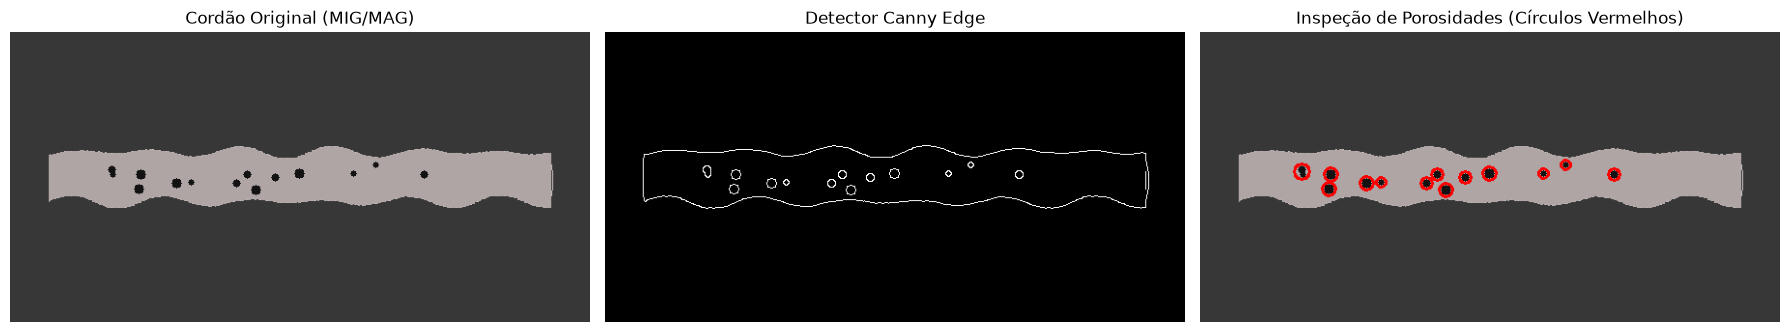

In [5]:
import base64

img_solda = cv2.imread(str(caminho_solda))
resultado_solda = inspecionar_cordao_solda(img_solda)

print("--- Diagnóstico Óptico do Cordão de Soldadura ---")
print(f"Status: {resultado_solda.get('status', 'N/A')}")
print(f"Taxa de Porosidade: {resultado_solda.get('taxa_porosidade_pct', 0)}%")
print(f"Poros Identificados: {resultado_solda.get('total_poros_detetados', 0)}")
print(f"Descontinuidade Estrutural: {'SIM' if resultado_solda.get('tem_descontinuidade') else 'NÃO'}")

# Recupera bordas Canny da matriz bruta ou decodifica do Base64
if "mascaras" in resultado_solda and "bordos_canny" in resultado_solda["mascaras"]:
    img_canny = resultado_solda["mascaras"]["bordos_canny"]
else:
    b64_canny = resultado_solda["imagens_b64"]["canny_b64"].split(",")[1]
    img_canny = cv2.imdecode(np.frombuffer(base64.b64decode(b64_canny), np.uint8), cv2.IMREAD_GRAYSCALE)

# Destaque visual dos poros detectados
img_anotada = img_solda.copy()
for poro in resultado_solda.get("detalhes_poros", []):
    cv2.circle(img_anotada, poro["centro"], poro["raio"] + 2, (0, 0, 255), 2)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(cv2.cvtColor(img_solda, cv2.COLOR_BGR2RGB))
axes[0].set_title("Cordão Original (MIG/MAG)")
axes[0].axis("off")

axes[1].imshow(img_canny, cmap="gray")
axes[1].set_title("Detector Canny Edge")
axes[1].axis("off")

axes[2].imshow(cv2.cvtColor(img_anotada, cv2.COLOR_BGR2RGB))
axes[2].set_title("Inspeção de Porosidades (Círculos Vermelhos)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

--- Diagnóstico Termográfico da HAZ ---
Risco de Trinca Térmica: SIM (CRÍTICO)
Área Crítica Sobreaquecida: 996 px (0.553%)
Hotspots Localizados: 1


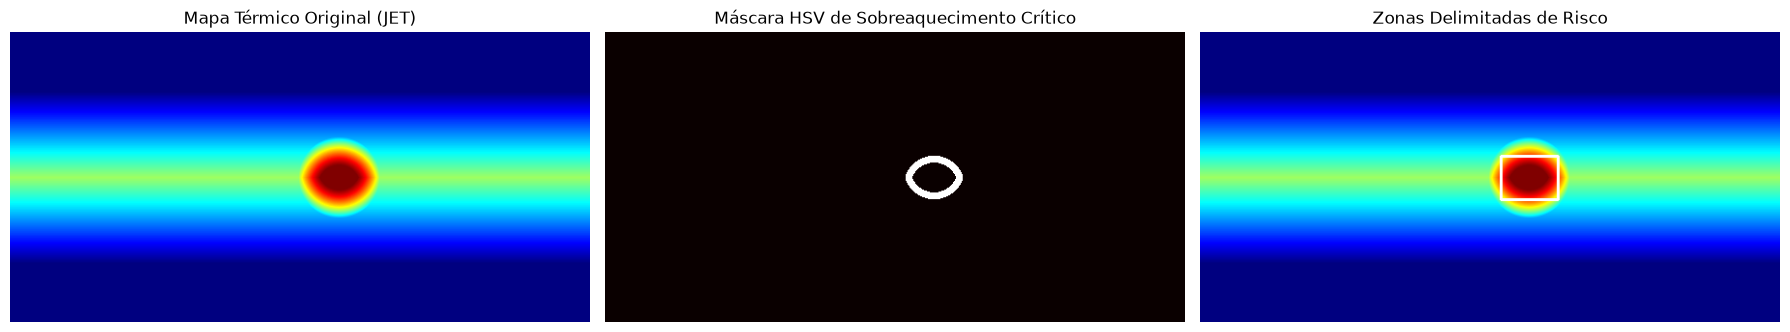

In [6]:
img_termo = cv2.imread(str(caminho_termo))
resultado_termo = analisar_haz_termica(img_termo)

print("--- Diagnóstico Termográfico da HAZ ---")
print(f"Risco de Trinca Térmica: {'SIM (CRÍTICO)' if resultado_termo['risco_trinca_termica'] else 'NÃO'}")
print(f"Área Crítica Sobreaquecida: {resultado_termo['area_critica_px']} px ({resultado_termo['percentagem_haz_critica']}%)")
print(f"Hotspots Localizados: {resultado_termo['quantidade_hotspots']}")

img_termo_anotada = img_termo.copy()
for spot in resultado_termo["hotspots"]:
    x, y, w, h = spot["bbox"]
    cv2.rectangle(img_termo_anotada, (x, y), (x + w, y + h), (255, 255, 255), 2)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(cv2.cvtColor(img_termo, cv2.COLOR_BGR2RGB))
axes[0].set_title("Mapa Térmico Original (JET)")
axes[0].axis("off")

axes[1].imshow(resultado_termo["mascara_critica"], cmap="hot")
axes[1].set_title("Máscara HSV de Sobreaquecimento Crítico")
axes[1].axis("off")

axes[2].imshow(cv2.cvtColor(img_termo_anotada, cv2.COLOR_BGR2RGB))
axes[2].set_title("Zonas Delimitadas de Risco")
axes[2].axis("off")

plt.tight_layout()
plt.show()